In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import (
    utils, stats, io_disk, plotting as pl,
    extremes
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
expt = '1pctCO2-cdr'

In [4]:
amoc_changes = {
    'CESM2': -4.46,
    'CNRM-ESM2-1': -3.35,
    'MIROC-ES2L': -2.31,
    'NorESM2-LM': -1.17,
    'UKESM1-0-LL': 1.25,
    'GFDL-ESM4': 1.88,
    'ACCESS-ESM1-5': 3.48,
    'CanESM5': 3.53
}
models_amoc_ordered = list(amoc_changes.keys())
models_amoc_ordered

['CESM2',
 'CNRM-ESM2-1',
 'MIROC-ES2L',
 'NorESM2-LM',
 'UKESM1-0-LL',
 'GFDL-ESM4',
 'ACCESS-ESM1-5',
 'CanESM5']

In [5]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=models_amoc_ordered)
    for name in ['exceedances_median_multimodel',
                 'branch_differences_median_multimodel',
                 'agreement',
                'gwl_period_extremes']
}

In [6]:
exceedances = ext_data['exceedances_median_multimodel']
differences = ext_data['branch_differences_median_multimodel']
agreement = ext_data['agreement']
ext_mon_data = utils.reduce_member_tree(ext_data['gwl_period_extremes'])

In [7]:
# plotting requires [
hot_mon_diff = {
    model: ds[expt] for model, ds in 
    extremes.ext_month_stat_diff(ext_mon_data, "heat", "mean").items()
}
cold_mon_diff = {
    model: ds[expt] for model, ds in 
    extremes.ext_month_stat_diff(ext_mon_data, "cold", "mean").items()
}

In [8]:
hot_mon_diff

{'CESM2': <xarray.Dataset> Size: 67kB
 Dimensions:  (lat: 90, lon: 180, gwl: 1)
 Coordinates:
   * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
   * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
   * gwl      (gwl) float64 8B 1.5
     extrema  <U4 16B 'heat'
 Data variables:
     tas      (gwl, lat, lon) float32 65kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>,
 'CNRM-ESM2-1': <xarray.Dataset> Size: 67kB
 Dimensions:  (lat: 90, lon: 180, gwl: 1)
 Coordinates:
   * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
   * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
   * gwl      (gwl) float64 8B 1.5
     extrema  <U4 16B 'heat'
 Data variables:
     tas      (gwl, lat, lon) float32 65kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>,
 'MIROC-ES2L': <xarray.Dataset> Size: 67kB
 Dimensions:  (lat: 90, lon: 180, gwl: 1)
 Coordinates:
   * lat      (lat) float64 720

In [9]:
heat_freq_differences = {
    model: differences[model][expt]['heat'] for model in models_amoc_ordered
}
cold_freq_differences = {
    model: differences[model][expt]['cold'] for model in models_amoc_ordered
}

## Plot

In [ ]:
fig = pl.plot_freq_and_intens_amoc_stereo(
    'Cold',
    cold_freq_differences,
    cold_mon_diff,
    1.5,
    'sigma1',
    freq_levels=np.linspace(-80, 80, 17),
    intens_levels=np.linspace(-3, 3, 13),
    amoc_changes=amoc_changes,
)

fig.savefig(
    FIG_DIR / "main" / "figure_6.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Plot mean changes grouped by AMOC sensitivity ##

In [12]:
AMOC_models = ["CESM2","MIROC-ES2L","NorESM2-LM",'CNRM-ESM2-1',]
non_AMOC_models = ['ACCESS-ESM1-5','CanESM5','GFDL-ESM4',"UKESM1-0-LL"]

In [14]:
ext_month_tas_differences = {
    model: d[expt] for model, d in
    extremes.ext_month_stat_diff(ext_mon_data, ["heat", "cold"], "mean").items()
}

In [15]:
AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

In [16]:
cbar_kwargs = {
        "fraction": 0.02, "aspect": 20,
        "label": "% Years", 'orientation': 'vertical',
        'location': 'right', 'pad': 0.01,
        'anchor': (0.5, -4), 'extend': 'both'
    }

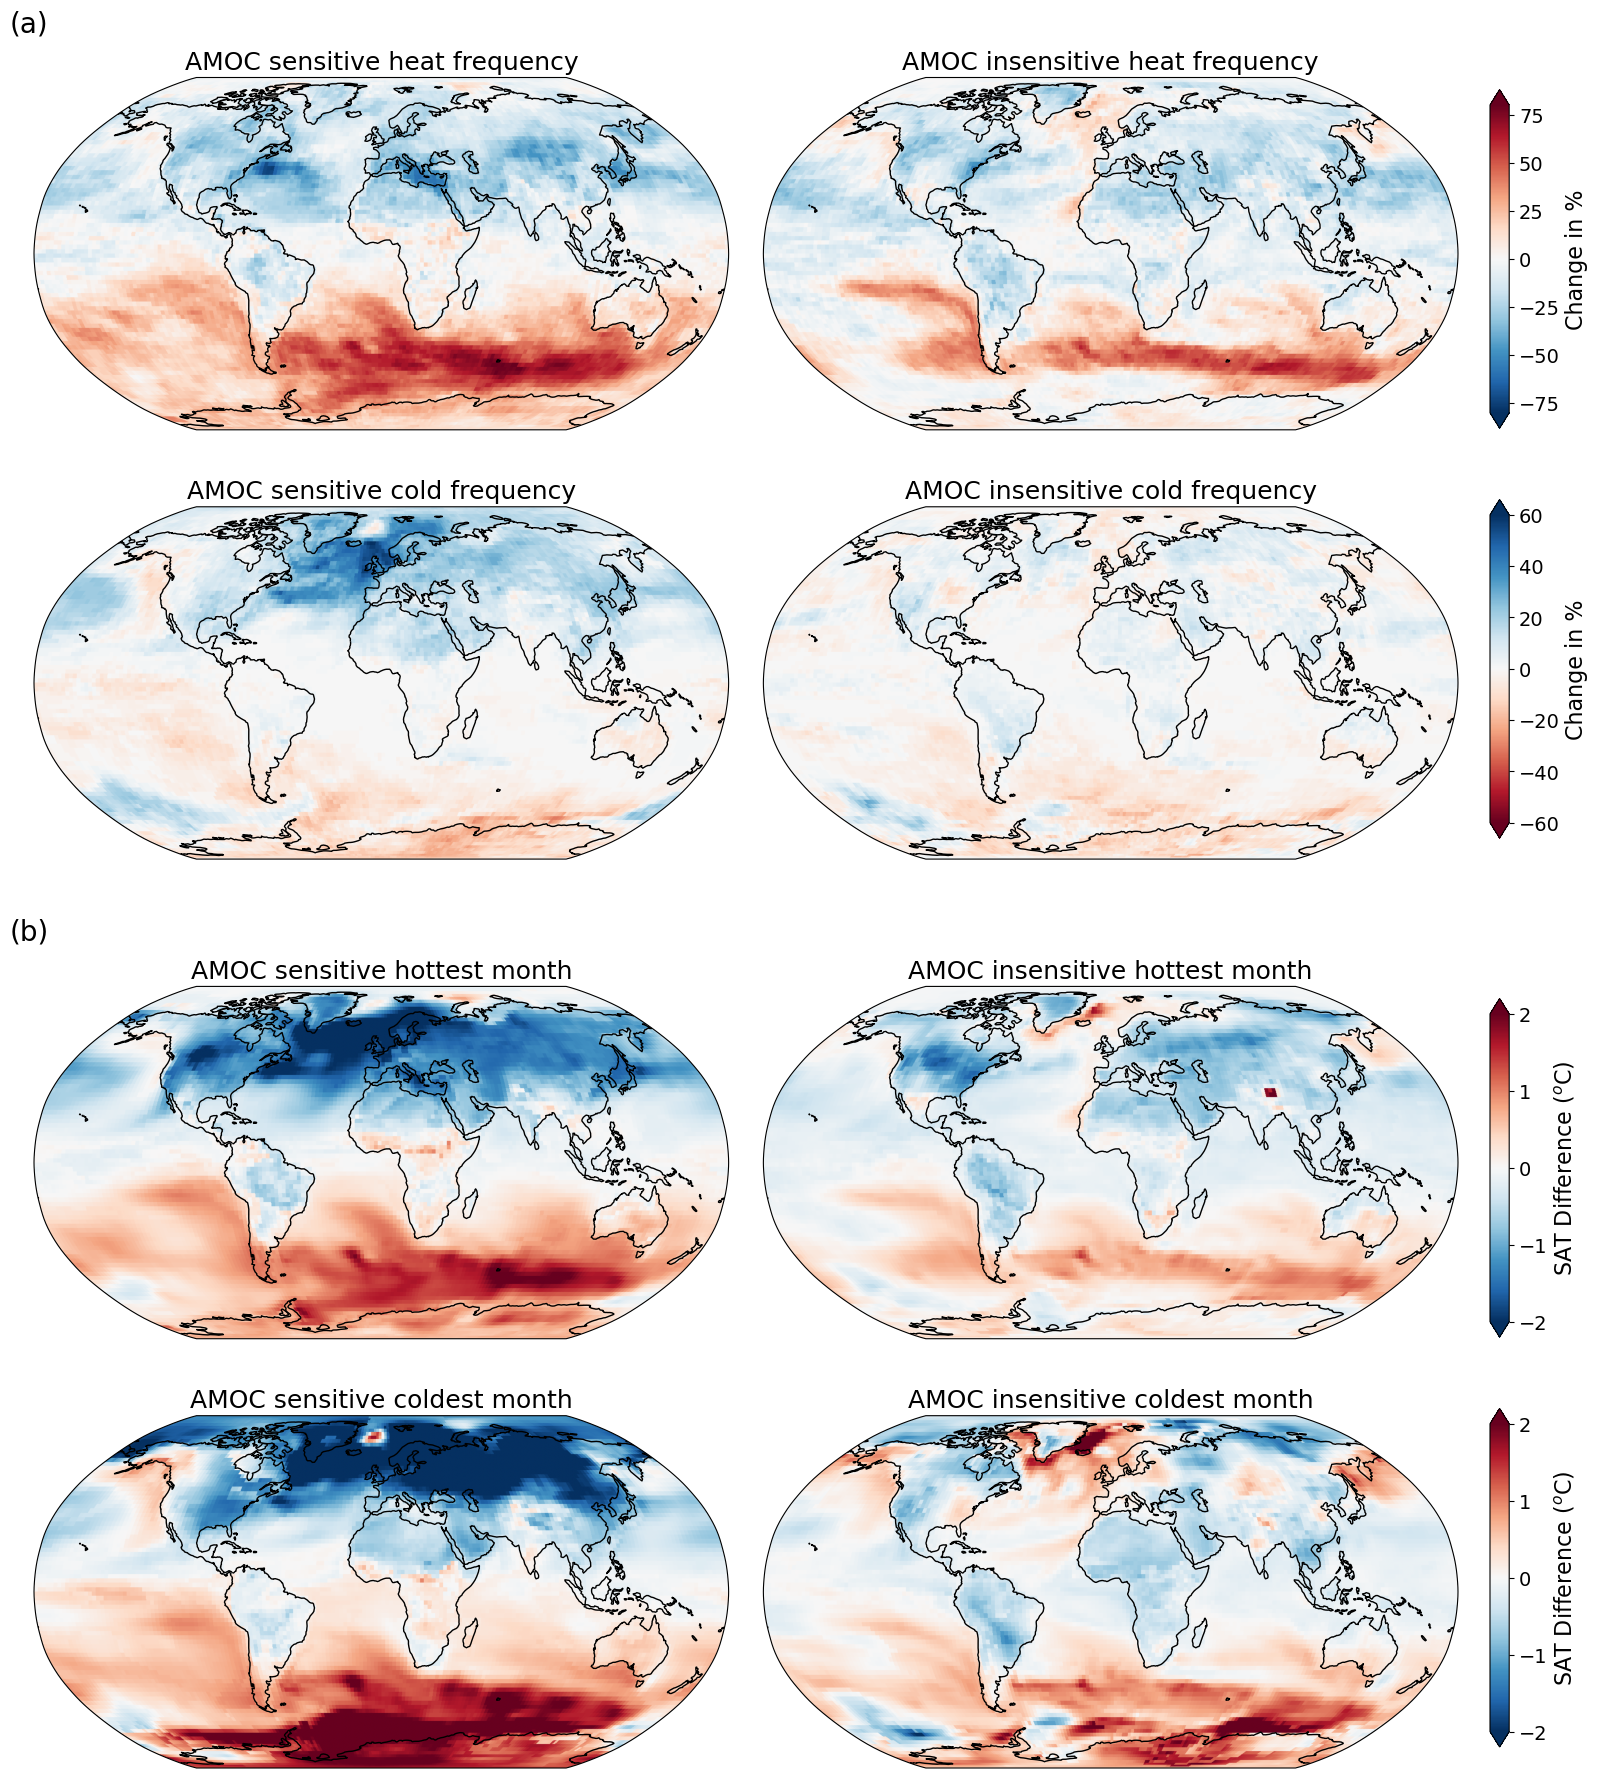

In [19]:
to_plot_hottest = {
    'AMOC sensitive hottest month':AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
    'AMOC insensitive hottest month':non_AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
}
to_plot_coldest = {
    'AMOC sensitive coldest month':AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
    'AMOC insensitive coldest month':non_AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
}

to_plot_heat_freq = {
    'AMOC sensitive heat frequency':AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
    'AMOC insensitive heat frequency':non_AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
}
to_plot_cold_freq = {
    'AMOC sensitive cold frequency':AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
    'AMOC insensitive cold frequency':non_AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
}

freq_rows = [
    {'data': to_plot_heat_freq,  'cmap': 'RdBu_r', 'vmin': -80, 'vmax': 80, 'cbar_label': 'Change in %'},
    {'data': to_plot_cold_freq,  'cmap': 'RdBu',   'vmin': -60, 'vmax': 60, 'cbar_label': 'Change in %'},
]
tas_rows = [
    {'data': to_plot_hottest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
    {'data': to_plot_coldest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
]

fig = pl.plot_mean_freq_and_tas_stacked(freq_rows, tas_rows)

fig.savefig(
    FIG_DIR / "main" / "figure_7.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)